<a href="https://colab.research.google.com/github/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA/blob/main/notebooks/00_comun/01_limites_municipios.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 · Límites de los municipios de la Altillanura

**Autora:** Michelle

**Fuente:** DANE – Marco Geoestadístico Nacional (MGN) 2025, nivel municipio.

**Propósito:** extraer los 7 municipios de la Altillanura, llevarlos a
EPSG:9377 (MAGNA-SIRGAS Origen Nacional) y guardarlos como capa base.

**Salida:** `datos/comunes/altillanura_municipios.gpkg`

## Paso 1. Preparar el entorno

In [ ]:
!pip install -q mapclassify

# Rutas del proyecto: funcionan en Colab y en local (ver 00_configuracion)
import os, sys, subprocess
EN_COLAB = 'google.colab' in sys.modules
REPO = 'https://github.com/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA.git'

if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    # Los datos crudos pesados (MGN, CSV de FIRMS, copia del ONI) siguen en Drive
    CRUDOS = '/content/drive/MyDrive/proyecto-altillanura-STDG/datos/crudos'
    RAIZ = '/content/Proyecto-ALTILLANURA'
    if not os.path.exists(RAIZ):
        !git clone -q {REPO} {RAIZ}
    # Mientras el PR #3 no esté unido a main, los datos comunes están en esta rama
    if not os.path.exists(f'{RAIZ}/datos/comunes/oni_mensual.csv'):
        !git -C {RAIZ} fetch -q origin feature/clima-fuego-datos
        !git -C {RAIZ} checkout -q feature/clima-fuego-datos
else:
    RAIZ = os.path.abspath(os.path.join('..', '..'))   # el cuaderno está en notebooks/<etapa>/
    CRUDOS = os.path.join(RAIZ, 'datos', 'crudos')

COMUNES = os.path.join(RAIZ, 'datos', 'comunes')
GRAFICAS = os.path.join(RAIZ, 'modulos', 'clima_fuego', 'graficas')
os.makedirs(GRAFICAS, exist_ok=True)

def traer(ruta):
    """Baja de DVC un archivo pesado del repo (por ejemplo un .gpkg) si todavía no está."""
    if os.path.exists(os.path.join(RAIZ, ruta)):
        return
    if EN_COLAB:
        from google.colab import auth
        auth.authenticate_user()
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'dvc[gs]'], check=True)
    subprocess.run([sys.executable, '-m', 'dvc', 'pull', '-q', ruta], cwd=RAIZ, check=True)
    print('Bajado de DVC:', ruta)

print('Raíz del repo:', RAIZ)
print('Crudos:', CRUDOS, '| existe:', os.path.exists(CRUDOS))

import os, glob, zipfile
import pandas as pd
import geopandas as gpd
import pyogrio
import matplotlib.pyplot as plt

print('Entorno listo')

## Paso 2. Descomprimir y ubicar el archivo del MGN

In [2]:
carpeta_mgn = f'{CRUDOS}/mgn'

for z in glob.glob(f'{carpeta_mgn}/*.zip'):
    with zipfile.ZipFile(z) as f:
        f.extractall(carpeta_mgn)
    print('Descomprimido:', os.path.basename(z))

archivos = (glob.glob(f'{carpeta_mgn}/**/*.gpkg', recursive=True)
            + glob.glob(f'{carpeta_mgn}/**/*.shp', recursive=True))
print('\nArchivos encontrados:')
for a in archivos:
    print(a)

Descomprimido: MGN2025_ADM_MPIO_GRAFICO_(Geopackage).zip

Archivos encontrados:
/content/drive/MyDrive/proyecto-altillanura-STDG/datos/crudos/mgn/MGN_ADM_MPIO_GRAFICO (Geopackage).gpkg


## Paso 3. Leer la capa de municipios y explorar su estructura

In [3]:
archivo_mpio = archivos[0]
print('Archivo:', archivo_mpio)

capas = pyogrio.list_layers(archivo_mpio)
print('\nCapas disponibles:')
for nombre, tipo in capas:
    print('  ', nombre, '|', tipo)

candidatas = [c[0] for c in capas
              if 'MPIO' in c[0].upper() or 'MUNICIPIO' in c[0].upper()]
capa_mpio = candidatas[0] if candidatas else capas[0][0]
print('\nCapa elegida:', capa_mpio)

mpios = gpd.read_file(archivo_mpio, layer=capa_mpio)
print('Número de registros:', len(mpios))
print('CRS:', mpios.crs)
print('Columnas:', list(mpios.columns))
mpios.head()

Archivo: /content/drive/MyDrive/proyecto-altillanura-STDG/datos/crudos/mgn/MGN_ADM_MPIO_GRAFICO (Geopackage).gpkg

Capas disponibles:
   MGN_ADM_MPIO_GRAFICO (Geopackage) | MultiPolygon

Capa elegida: MGN_ADM_MPIO_GRAFICO (Geopackage)
Número de registros: 1122
CRS: EPSG:4326
Columnas: ['dpto_ccdgo', 'mpio_ccdgo', 'mpio_cdpmp', 'dpto_cnmbr', 'mpio_cnmbr', 'mpio_crslc', 'mpio_tipo', 'mpio_narea', 'mpio_nano', 'shape_Leng', 'shape_Area', 'geometry']


,dpto_ccdgo,mpio_ccdgo,mpio_cdpmp,dpto_cnmbr,mpio_cnmbr,mpio_crslc,mpio_tipo,mpio_narea,mpio_nano,shape_Leng,shape_Area,geometry
0,05,001,05001,ANTIOQUIA,MEDELLÍN,1965,MUNICIPIO,374.741484,2025,1.035380,0.030608,"MULTIPOLYGON (((-75.4857 6.20163, -75.48567 6...."
1,05,002,05002,ANTIOQUIA,ABEJORRAL,1814,MUNICIPIO,506.959782,2024,1.158504,0.041384,"MULTIPOLYGON (((-75.46938 5.94575, -75.46897 5..."
2,05,004,05004,ANTIOQUIA,ABRIAQUÍ,1912,MUNICIPIO,296.974188,2025,0.810667,0.024253,"MULTIPOLYGON (((-76.09047 6.74542, -76.09066 6..."
3,05,021,05021,ANTIOQUIA,ALEJANDRÍA,Decreto departamental 304 de 1907,MUNICIPIO,128.856431,2024,0.705200,0.010535,"MULTIPOLYGON (((-75.0332 6.41586, -75.03313 6...."
4,05,030,05030,ANTIOQUIA,AMAGÁ,1912,MUNICIPIO,84.117145,2024,0.445533,0.006867,"MULTIPOLYGON (((-75.67587 6.08561, -75.6754 6...."


## Paso 4. Filtrar los 7 municipios por código DIVIPOLA
DIVIPOLA es la codificación oficial del DANE: 2 dígitos de departamento
+ 3 de municipio. Filtrar por código evita errores con tildes o nombres.

In [4]:
ALTILLANURA = ['50573', '50568', '50325',            # Meta
               '99524', '99773', '99001', '99624']   # Vichada

alti = mpios[mpios['mpio_cdpmp'].isin(ALTILLANURA)].copy()

print('Municipios encontrados:', len(alti))
alti[['mpio_cdpmp', 'mpio_cnmbr', 'dpto_cnmbr', 'mpio_tipo', 'mpio_narea']]

Municipios encontrados: 7


,mpio_cdpmp,mpio_cnmbr,dpto_cnmbr,mpio_tipo,mpio_narea
700,50325,MAPIRIPÁN,META,MUNICIPIO,11917.478785
706,50568,PUERTO GAITÁN,META,MUNICIPIO,17200.784014
707,50573,PUERTO LÓPEZ,META,MUNICIPIO,6898.236150
1118,99001,PUERTO CARREÑO,VICHADA,MUNICIPIO,12142.323352
1119,99524,LA PRIMAVERA,VICHADA,MUNICIPIO,18492.107241
1120,99624,SANTA ROSALÍA,VICHADA,MUNICIPIO,3679.005021
1121,99773,CUMARIBO,VICHADA,MUNICIPIO,65319.285137


## Paso 5. Reproyectar a EPSG:9377 y calcular áreas
El área solo es válida en un sistema proyectado (metros), no en grados.
Se compara con el área oficial del DANE (`mpio_narea`) como control.

In [5]:
alti = alti.to_crs(9377)

alti['area_km2'] = alti.geometry.area / 1e6
alti['area_ha'] = alti.geometry.area / 1e4
alti['dif_vs_dane_%'] = (alti['area_km2'] / alti['mpio_narea'] - 1) * 100

tabla = (alti[['mpio_cdpmp', 'mpio_cnmbr', 'dpto_cnmbr',
               'area_km2', 'mpio_narea', 'dif_vs_dane_%']]
         .sort_values('area_km2', ascending=False))
print(tabla.round(2).to_string(index=False))

print(f"\nCRS: {alti.crs}")
print(f"Área total: {alti['area_km2'].sum():,.0f} km² "
      f"({alti['area_ha'].sum()/1e6:.1f} millones de ha)")

mpio_cdpmp     mpio_cnmbr dpto_cnmbr  area_km2  mpio_narea  dif_vs_dane_%
     99773       CUMARIBO    VICHADA  65319.29    65319.29            0.0
     99524   LA PRIMAVERA    VICHADA  18492.11    18492.11            0.0
     50568  PUERTO GAITÁN       META  17200.78    17200.78            0.0
     99001 PUERTO CARREÑO    VICHADA  12142.32    12142.32            0.0
     50325      MAPIRIPÁN       META  11917.48    11917.48            0.0
     50573   PUERTO LÓPEZ       META   6898.24     6898.24           -0.0
     99624  SANTA ROSALÍA    VICHADA   3679.01     3679.01            0.0

CRS: EPSG:9377
Área total: 135,649 km² (13.6 millones de ha)


## Paso 6. Mapa de control

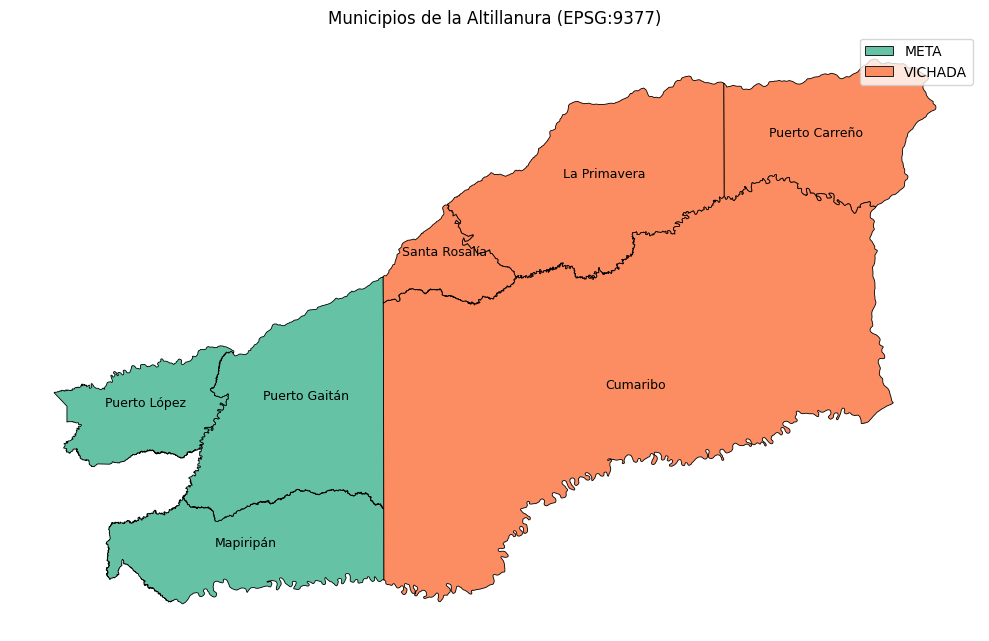

In [6]:
fig, ax = plt.subplots(figsize=(10, 7))
alti.plot(ax=ax, column='dpto_cnmbr', cmap='Set2',
          edgecolor='black', linewidth=0.6, legend=True)

for _, fila in alti.iterrows():
    p = fila.geometry.representative_point()
    ax.annotate(fila['mpio_cnmbr'].title(), (p.x, p.y),
                ha='center', fontsize=9)

ax.set_title('Municipios de la Altillanura (EPSG:9377)')
ax.set_axis_off()
plt.tight_layout()

os.makedirs(GRAFICAS, exist_ok=True)
plt.savefig(f'{GRAFICAS}/01_mapa_municipios.png', dpi=150)
plt.show()

## Paso 7. Guardar la capa base

In [7]:
salida = alti[['mpio_cdpmp', 'mpio_cnmbr', 'dpto_ccdgo', 'dpto_cnmbr',
               'mpio_narea', 'area_km2', 'area_ha', 'geometry']]

salida.to_file(f'{COMUNES}/altillanura_municipios.gpkg',
               layer='municipios', driver='GPKG')
salida.drop(columns='geometry').to_csv(
    f'{COMUNES}/altillanura_municipios.csv', index=False)

check = gpd.read_file(f'{COMUNES}/altillanura_municipios.gpkg')
print('Guardado OK |', len(check), 'municipios | CRS:', check.crs)

Guardado OK | 7 municipios | CRS: EPSG:9377
